# Project 2: Training a Better RL Hockey Player

The goal of this assignment is to design and train a capable reinforcement learning (RL) hockey player. You will modify this notebook, adjust the environment dynamics, shape the reward structures, and train different versions of your policy.

## Your Three Tasks

### Task 1: The Initial "Bad" Hockey Player
Demonstrate that the base code works by training an agent using the Proximal Policy Optimization (PPO) algorithm with the provided notebook defaults. Save the generated GIF of your agent's initial performance to serve as a baseline comparison.

### Task 2: Fixed Goal Scoring
Modify the reward structure in the `step()` function so that the player is incentivized and successfully trained to score goals. Prove that your policy works by providing example GIFs and a plotted reward chart demonstrating training progress.

### Task 3: Randomized Goal Placement
Update the initialization and `reset()` logic so that the goal's horizontal position is randomized (moved left and right) at the start of each episode. Train your agent to score on this dynamic target and document the results.

---

## Submission Guidelines

Submit your final Jupyter Notebook (`.ipynb` file) alongside a rendered HTML or PDF version. Additionally, submit all supporting GIFs using clear, reasonable naming conventions (e.g., `FixedGoal1.gif`, `failure1.gif`).

At the very end of your notebook, you must create markdown cells containing the following three sections:

**1. Summary of RL Training Tasks**  
For each of the three tasks (Initial Bad Player, Fixed Goal, Random Start Goal), describe your training and evaluation process. This must include:
* A brief text description of your approach.
* GIF demonstrations of the agent.
* Training details (e.g., charts of metrics over time and the total number of episodes trained).

**2. Reflection on Failures**  
Did your team experience any failures while training? Document them here and include example GIFs where applicable. You can discuss failed ideas for improving training, unexpected lack of improvement, and any experimental configurations you attempted in order to build your understanding.

**3. Reflection on Key Changes**  
Reflect on the most impactful changes that led to your eventual success. What specific adjustments to the training parameters, environment (e.g., `step` function, observation space), or reward shaping made the biggest difference? Finally, if you were to redo this project from scratch, what would you do differently?

---

## Resources
* [Ray RLlib Algorithms: PPO Explainer](https://docs.ray.io/en/latest/rllib/rllib-algorithms.html#ppo)
* [Proximal Policy Optimization Algorithms (Original Paper)](https://arxiv.org/abs/1707.06347)


# Install Block

This block will install necessary libraries for this project.

In [1]:


# 1. STRIP CONFLICTING FRAMEWORKS FIRST
!pip uninstall -y jax jaxlib tensorflow flax

# 2. INSTALL UPDATED DEPENDENCIES
!pip install -U ray[rllib]>=2.45.0
!pip install -U gymnasium
!pip install -U mujoco
!pip install -U moderngl gputil lz4

!pip install seaborn
!pip install torch
!pip install gymnasium
!pip install "gymnasium[mujoco]"
!pip install ray
!pip install dm-tree
!pip install "ray[tune]"

# 3. INSTALL SYSTEM GRAPHICS LIBRARIES
!apt-get update > /dev/null 2>&1
!apt-get install -y \
   libgl1-mesa-dev \
   libgl1 \
   libglew-dev \
   libosmesa6-dev \
   software-properties-common > /dev/null 2>&1

!apt-get install -y patchelf xvfb python-opengl ffmpeg > /dev/null 2>&1

# 4. IMPORTS
from __future__ import annotations
import random
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from torch.distributions.normal import Normal
import gymnasium as gym

zsh:1: no matches found: ray[rllib]


In [9]:
# from google.colab import drive
# drive.mount('/content/drive')

# Specify the path to your checkpoints folder
models_path = 'models/'

# Environment / Main Block

This block containss the environment. It includes the step and reward function. It requires the hockey.xml file. In my personal Google Colab, this is placed in a top level folder called "checkpoints/models".

In [33]:
import numpy as np
from gymnasium.spaces import Discrete, Box
from gymnasium import utils
from gymnasium.envs.mujoco import MujocoEnv
import os

RANDOM_GOAL_TOGGLE = False #used across cells.

class HockeyEnv(MujocoEnv, utils.EzPickle):
    metadata = {
        "render_modes": ["human", "rgb_array", "depth_array"],
        "render_fps": 50,
    }

    def __init__(self, episode_len=300, randomize_goal=False, **kwargs):
        utils.EzPickle.__init__(self, episode_len=episode_len, randomize_goal=randomize_goal, **kwargs)

        # Observation space: player pos (2), player vel (2), puck pos (2), puck vel (2), goal pos (2) = 10 dimensions
        observation_space = Box(low=-np.inf, high=np.inf, shape=(10,), dtype=np.float32)

        self.episode_len = episode_len
        self.randomize_goal = randomize_goal

        MujocoEnv.__init__(
            self,
            os.path.abspath(models_path + "hockey.xml"),
            10,
            observation_space=observation_space,
            **kwargs
        )
        self.step_number = 0.0
        self.action_space = Discrete(4)

    def step(self, a):
        # Base time penalty to encourage scoring quickly
        reward = -0.1 # modified from -0.1

        if a == 0:   force = [0, 1]
        elif a == 1: force = [0, -1]
        elif a == 2: force = [-1, 0]
        elif a == 3: force = [1, 0]

        scaled_force = np.array(force) * 10

        # Adding positions before simulation
        prev_player_pos = np.array([self.data.joint("player_x").qpos[0], self.data.joint("player_y").qpos[0]])
        prev_puck_pos = np.array([self.data.joint("puck_joint").qpos[0], self.data.joint("puck_joint").qpos[1]])
        prev_goal_pos = np.array([self.data.joint("goal_joint").qpos[0], self.data.joint("goal_joint").qpos[1]])
        prev_player_puck_dist = np.linalg.norm(prev_player_pos - prev_puck_pos)
        prev_puck_goal_dist = np.linalg.norm(prev_puck_pos - prev_goal_pos)

        self.do_simulation(scaled_force, self.frame_skip)
        self.step_number += 1.0

        # Extract Physical Coordinates directly from joints
        player_pos = np.array([self.data.joint("player_x").qpos[0], self.data.joint("player_y").qpos[0]])
        puck_pos = np.array([self.data.joint("puck_joint").qpos[0], self.data.joint("puck_joint").qpos[1]])
        goal_pos = np.array([self.data.joint("goal_joint").qpos[0], self.data.joint("goal_joint").qpos[1]])

        # Dense Reward Shaping
        dist_player_to_puck = np.linalg.norm(player_pos - puck_pos)
        dist_puck_to_goal = np.linalg.norm(puck_pos - goal_pos)

        # Modifying rewards
        reward += 8.0 * (prev_player_puck_dist - dist_player_to_puck)
        reward += 50.0 * (prev_puck_goal_dist - dist_puck_to_goal)

        if prev_player_puck_dist >= 0.25 and dist_player_to_puck < 0.25:
            reward += 2.0

        # reward -= (dist_player_to_puck * 0.1) # Encourage moving to the puck
        # reward -= (dist_puck_to_goal * 0.5)   # Encourage moving the puck to the goal

        done = False

        # Sparse Reward: Goal Scored
        if dist_puck_to_goal < 0.25:
            reward += 1000.0
            done = True

        # Out of bounds penalty for player
        pos_min, pos_max = -2.0, 2.0
        if player_pos[0] > pos_max or player_pos[0] < pos_min or player_pos[1] > pos_max or player_pos[1] < pos_min:
            reward -= 20.0 # was 500.0, decreased penalty to 50.0, decreased again to 20.0
            done = True

        obs = self._get_obs()

        truncated = False
        if self.step_number is not None and self.episode_len is not None:
            if float(self.step_number) >= float(self.episode_len):
                truncated = True

        return obs, reward, done, truncated, {}

    def reset_model(self):
        self.step_number = 0.0

        # Safely reset base state without corrupting freejoint quaternions
        qpos = self.init_qpos.copy()
        qvel = self.init_qvel.copy()

        # Add slight noise only to the player slide joints (indexes 0 and 1)
        qpos[0] += self.np_random.uniform(low=-0.01, high=0.01)
        qpos[1] += self.np_random.uniform(low=-0.01, high=0.01)
        qvel[0] += self.np_random.uniform(low=-0.01, high=0.01)
        qvel[1] += self.np_random.uniform(low=-0.01, high=0.01)

        self.set_state(qpos, qvel)
        self.data.joint("puck_joint").qpos[0] = 0
        self.data.joint("puck_joint").qpos[1] = 0

        # Randomize Goal Physical Position
        if self.randomize_goal:
            # Field width is roughly -1 to 1. Randomize X across the length of the field.
            goal_x = self.np_random.uniform(low=-0.8, high=0.8)
            # Keep Y on the opponent's side of the field
            goal_y = self.np_random.uniform(low=0.5, high=0.925)
            self.data.joint("goal_joint").qpos[0] = goal_x
            self.data.joint("goal_joint").qpos[1] = goal_y
        else:
            # Reset to the default location from hockey.xml
            self.data.joint("goal_joint").qpos[0] = 0.0
            self.data.joint("goal_joint").qpos[1] = 0.925

        return self._get_obs()

    def _get_obs(self):
        player_qpos = np.array([self.data.joint("player_x").qpos[0], self.data.joint("player_y").qpos[0]])
        player_qvel = np.array([self.data.joint("player_x").qvel[0], self.data.joint("player_y").qvel[0]])

        # Freejoints have 7 position elements and 6 velocity elements. We only want X and Y.
        puck_qpos = np.array([self.data.joint("puck_joint").qpos[0], self.data.joint("puck_joint").qpos[1]])
        puck_qvel = np.array([self.data.joint("puck_joint").qvel[0], self.data.joint("puck_joint").qvel[1]])

        goal_qpos = np.array([self.data.joint("goal_joint").qpos[0], self.data.joint("goal_joint").qpos[1]])

        # Flatten state into exactly 10-dimensional observation array
        obs = np.concatenate((player_qpos, player_qvel, puck_qpos, puck_qvel, goal_qpos), axis=0)
        return obs

## Manual Test Block
This block can be used to test your reward function. It renders a single episode as a GIF, controlled manually by a series of "actions"

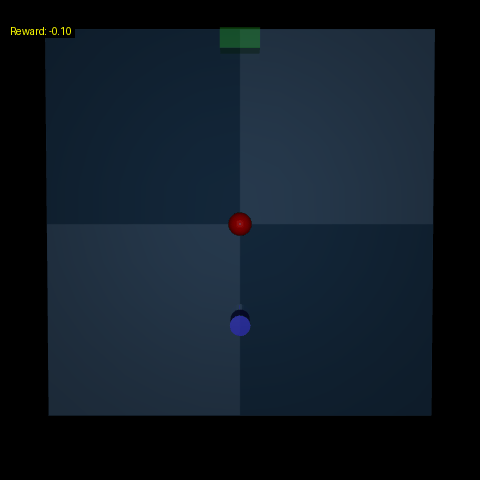

In [34]:
import os
# os.environ["MUJOCO_GL"] = "osmesa"

### - Macbook specific
os.environ.pop("MUJOCO_GL", None)
os.environ.pop("PYOPENGL_PLATFORM", None)
###

from IPython.display import Image as IPythonImage, display
from PIL import Image as PILImage, ImageDraw
import imageio
import numpy as np

env = HockeyEnv(render_mode="rgb_array", camera_name="topdown", randomize_goal=RANDOM_GOAL_TOGGLE)
### this line tests out a series of discrete action manually. This can help you ensure your reward function is working correctly visually.
go_right_then_left = ([[3]]*10 + [[0]]*10 + [[2]]*10 + [[2]]*10) * 2

def add_text_to_frame(frame, text, x, y):
    img = PILImage.fromarray(frame)
    draw = ImageDraw.Draw(img)
    bbox = draw.textbbox((x, y), text)
    padded_bbox = [bbox[0]-2, bbox[1]-2, bbox[2]+2, bbox[3]+2]
    draw.rectangle(padded_bbox, fill="black")
    draw.text((x, y), text, fill="yellow")
    return np.array(img)

def rerun_best_episode(env, best_actions):
    obs, info = env.reset()
    frames = []
    total_reward = 0
    for action in best_actions:
        discrete_action = int(action[0])
        obs, reward, terminated, truncated, ddd = env.step(discrete_action)
        total_reward += reward
        frame = env.render()
        frame_with_text = add_text_to_frame(frame, f"Reward: {total_reward:.2f}", 10, 25)
        frames.append(frame_with_text)
    env.close()
    return frames

frames = rerun_best_episode(env, go_right_then_left)
imageio.mimsave('manual.gif', frames, fps=20, loop=0)
display(IPythonImage(filename='manual.gif'))

## Training Block

An example training block that runs, reports, and charts the results from the PPO algorithm.

Iteration 90 | Checkpoint: TrainingResult(checkpoint=Checkpoint(filesystem=local, path=/Users/vallipaladugu/Desktop/College/Fall_2026/ECE517/Project-2/models/checklambda.08), metrics={'timers': {'training_iteration': 0.4074899197833768, 'restore_env_runners': 2.0622901469554474e-05, 'training_step': 0.40735022523056397, 'env_runner_sampling_timer': 0.09219922713109065, 'learner_update_timer': 0.3136410621000027, 'synch_weights': 0.0013679603944682613, 'synch_env_connectors': 0.0012895731878293998}, 'env_runners': {'module_to_env_connector': {'timers': {'connectors': {'un_batch_to_individual_items': np.float64(4.938466541835026e-06), 'tensor_to_numpy': np.float64(1.3899076417984503e-05), 'normalize_and_clip_actions': np.float64(9.4283513363649e-06), 'remove_single_ts_time_rank_from_batch': np.float64(6.084242247993155e-07), 'get_actions': np.float64(3.854682303393925e-05), 'listify_data_for_vector_env': np.float64(3.496986448164468e-06)}}, 'connector_pipeline_timer': np.float64(9.993430

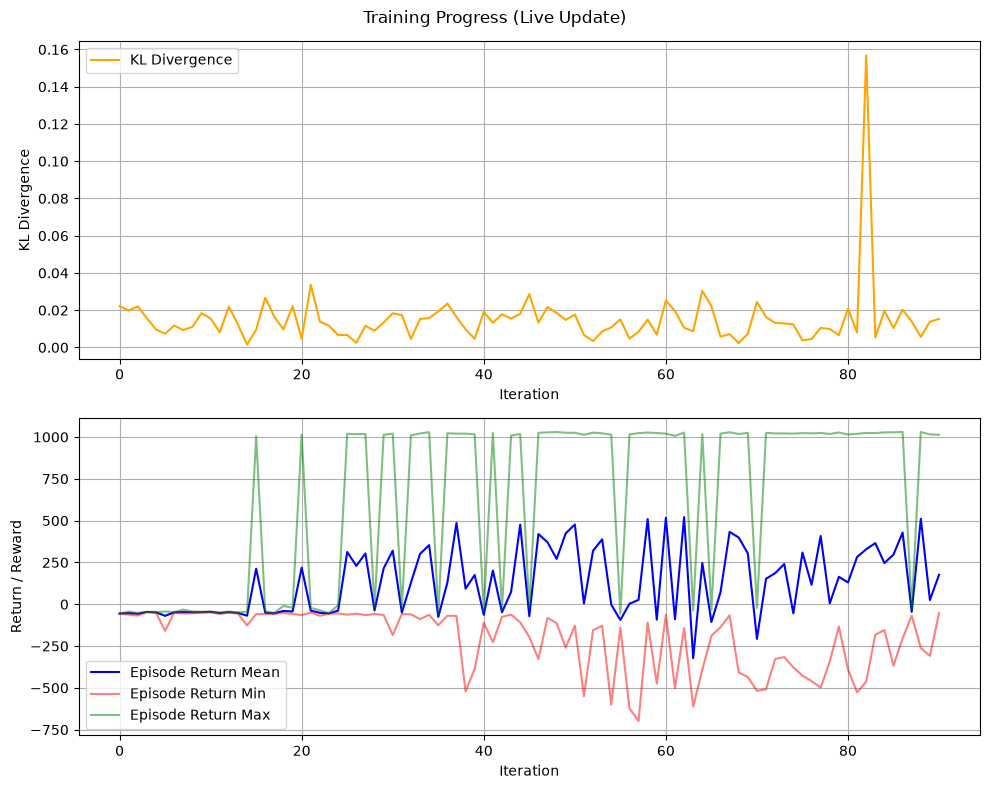

Final checkpoint saved in directory TrainingResult(checkpoint=Checkpoint(filesystem=local, path=/Users/vallipaladugu/Desktop/College/Fall_2026/ECE517/Project-2/models/checklambda.08), metrics={'timers': {'training_iteration': 0.4034901333903737, 'restore_env_runners': 1.9334069255877615e-05, 'training_step': 0.40335715344445566, 'env_runner_sampling_timer': 0.0917463104285514, 'learner_update_timer': 0.3101100566963804, 'synch_weights': 0.0013581824246117627, 'synch_env_connectors': 0.001253552078425602}, 'env_runners': {'module_to_env_connector': {'timers': {'connectors': {'un_batch_to_individual_items': np.float64(4.9903124050413686e-06), 'tensor_to_numpy': np.float64(1.3882047010379154e-05), 'normalize_and_clip_actions': np.float64(9.273278371655353e-06), 'remove_single_ts_time_rank_from_batch': np.float64(5.660850188598464e-07), 'get_actions': np.float64(3.714757269612387e-05), 'listify_data_for_vector_env': np.float64(3.4229883107007184e-06)}}, 'connector_pipeline_timer': np.float

In [35]:
from ray.rllib.algorithms.ppo import PPOConfig
from ray import tune
import os
import numpy as np
import math
import matplotlib.pyplot as plt
from IPython.display import clear_output

plt.rcParams["figure.figsize"] = (10, 5)

num_iterations = 100
batch_size = 512
env = HockeyEnv(render_mode="rgb_array", camera_name="topdown", randomize_goal=RANDOM_GOAL_TOGGLE)

tune.register_env("my_env", lambda config: HockeyEnv(randomize_goal=True))

config = (
    PPOConfig()
    .environment(env="my_env")
    .training(train_batch_size=batch_size, lambda_=1.0)
    # .resources(num_gpus=0.05) # Uncomment if using GPU
)

if 'algo' in globals():
    algo.stop()
    del algo

algo = config.build()

# checkpoint_path = 'models/checklambda.08'
checkpoint_path = os.path.abspath("models/checklambda.08") # Macbook specific
os.makedirs(checkpoint_path, exist_ok=True)

kl_divergence_history = []
reward_mean_history = []
reward_min_history = []
reward_max_history = []

iterations_kl = []
iterations_rew = []

for i in range(num_iterations):
    result = algo.train()

    # 1. Extract KL Divergence from new 'learners' dictionary structure
    learners_dict = result.get("learners", {}).get("default_policy", {})
    kl = learners_dict.get("kl", learners_dict.get("mean_kl_loss", None))

    if kl is not None and not math.isnan(kl):
        kl_divergence_history.append(float(kl))
        iterations_kl.append(i)  

    # 2. Extract Episode Returns from 'env_runners' dictionary structure
    env_runners = result.get("env_runners", {})
    rew_mean = env_runners.get("episode_return_mean")
    rew_min = env_runners.get("episode_return_min")
    rew_max = env_runners.get("episode_return_max")

    if rew_mean is not None and not math.isnan(rew_mean):
        reward_mean_history.append(float(rew_mean))
        reward_min_history.append(float(rew_min if rew_min is not None else rew_mean))
        reward_max_history.append(float(rew_max if rew_max is not None else rew_mean))
        iterations_rew.append(i)

    # Live Plotting - Redraws every 10 iterations
    if i % 10 == 0:
        checkpoint_dir = algo.save(checkpoint_path)

        clear_output(wait=True)
        print(f"Iteration {i} | Checkpoint: {checkpoint_dir} | Mean Return: {rew_mean:.2f}")

        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
        fig.suptitle("Training Progress (Live Update)")

        if iterations_kl:
            ax1.plot(iterations_kl, kl_divergence_history, label="KL Divergence", color="orange")
            ax1.set_xlabel("Iteration")
            ax1.set_ylabel("KL Divergence")
            ax1.legend()
            ax1.grid(True)
        else:
            ax1.set_title("KL Divergence (Waiting for learner metrics...)")

        if iterations_rew:
            ax2.plot(iterations_rew, reward_mean_history, label="Episode Return Mean", color="blue")
            ax2.plot(iterations_rew, reward_min_history, label="Episode Return Min", color="red", alpha=0.5)
            ax2.plot(iterations_rew, reward_max_history, label="Episode Return Max", color="green", alpha=0.5)
            ax2.set_xlabel("Iteration")
            ax2.set_ylabel("Return / Reward")
            ax2.legend()
            ax2.grid(True)

        plt.tight_layout()
        plt.show()

final_checkpoint_dir = algo.save(checkpoint_path)
print(f"Final checkpoint saved in directory {final_checkpoint_dir}")

## Test and Render Block

The following code creates 10 example run GIFs based on the policy in the "algo" variable.



Saved tested_episode_0.gif


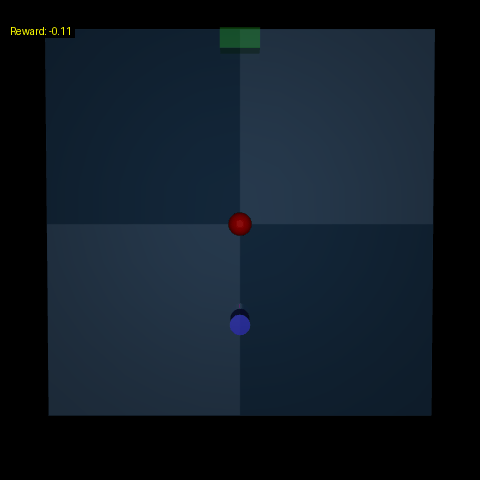

Saved tested_episode_1.gif


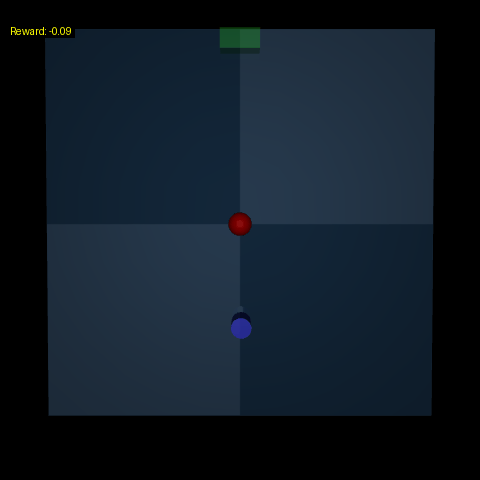

Saved tested_episode_2.gif


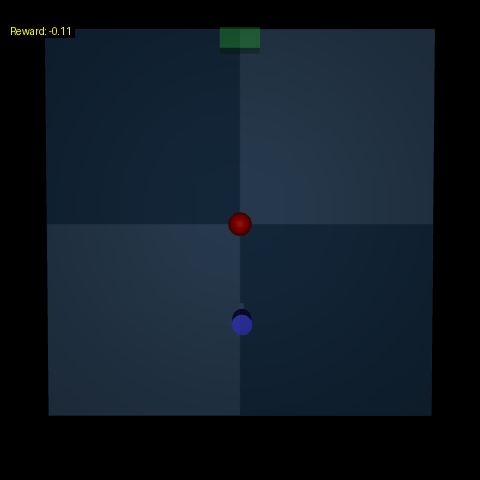

Saved tested_episode_3.gif


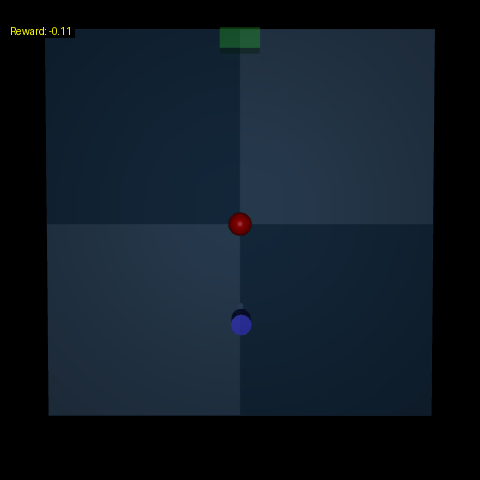

Saved tested_episode_4.gif


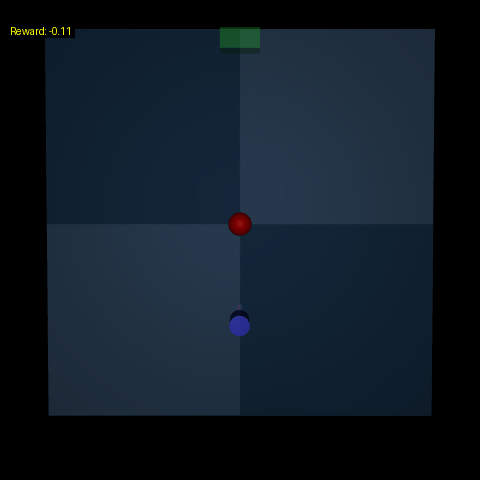

Saved tested_episode_5.gif


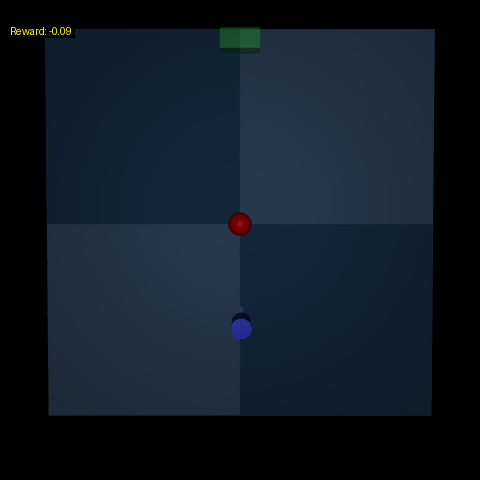

Saved tested_episode_6.gif


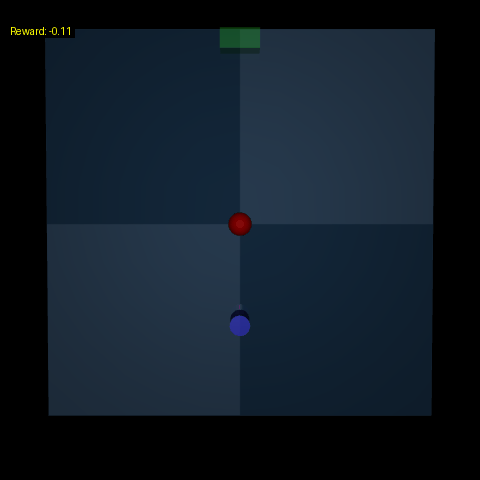

Saved tested_episode_7.gif


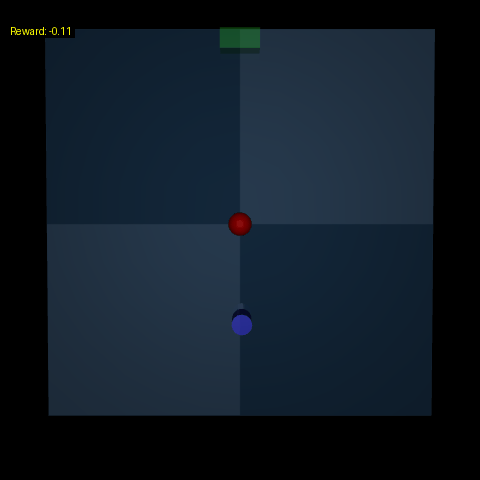

Saved tested_episode_8.gif


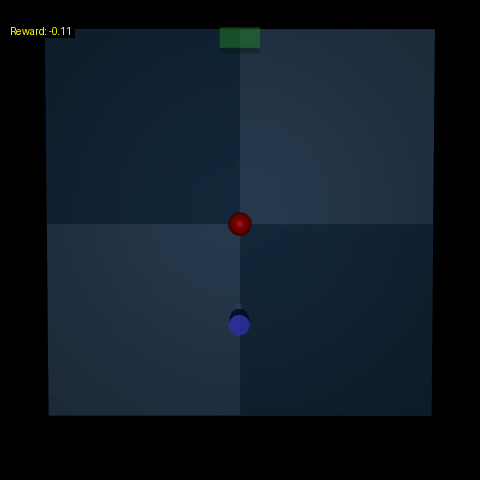

Saved tested_episode_9.gif


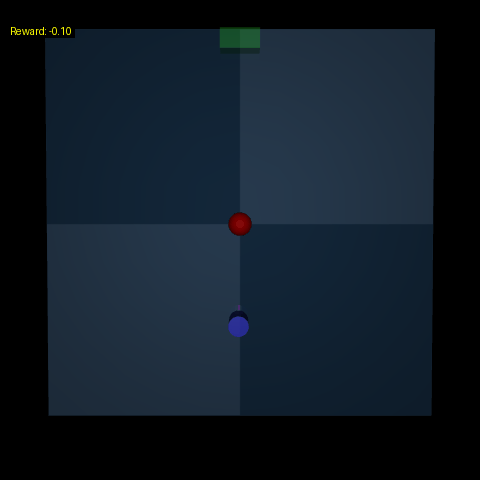

In [36]:
# import os
# os.environ["MUJOCO_GL"] = "osmesa"

from IPython.display import Image as IPythonImage, display
from PIL import Image as PILImage, ImageDraw
import imageio
import numpy as np
import torch # Required for the new RLModule inference API

example_runs = 10
prepend_to_gif_file = "tested_episode_"

# Instantiate the environment
env = HockeyEnv(render_mode="rgb_array", camera_name="topdown", randomize_goal=RANDOM_GOAL_TOGGLE)

def add_text_to_frame(frame, text, x, y):
    img = PILImage.fromarray(frame)
    draw = ImageDraw.Draw(img)
    bbox = draw.textbbox((x, y), text)
    padded_bbox = [bbox[0]-2, bbox[1]-2, bbox[2]+2, bbox[3]+2]
    draw.rectangle(padded_bbox, fill="black")
    draw.text((x, y), text, fill="yellow")
    return np.array(img)

def render_policy_episode(env, algo, steps=200):
    obs, info = env.reset()
    frames = []
    total_reward = 0

    # MODERN RAY FIX: Extract the raw PyTorch neural network module directly
    module = algo.get_module("default_policy")
    device = next(module.parameters()).device # Check if the model is on CPU or GPU

    for _ in range(steps):
        # 1. Convert the observation to a PyTorch tensor with a batch dimension of 1
        obs_tensor = torch.tensor([obs], dtype=torch.float32).to(device)

        # 2. Run the tensor through the network without calculating gradients
        with torch.no_grad():
            out = module.forward_inference({"obs": obs_tensor})

            # 3. Extract the discrete action
            if "action_dist_inputs" in out:
                # Take the argmax to exploit the best deterministic action
                discrete_action = int(torch.argmax(out["action_dist_inputs"], dim=-1).item())
            elif "actions" in out:
                discrete_action = int(out["actions"][0].item())
            else:
                # Fallback for unexpected dictionary formats
                discrete_action = int(list(out.values())[0][0].item())

        # Step the environment
        obs, reward, terminated, truncated, ddd = env.step(discrete_action)
        total_reward += reward

        frame = env.render()
        frame_with_text = add_text_to_frame(frame, f"Reward: {total_reward:.2f}", 10, 25)
        frames.append(frame_with_text)

        if terminated or truncated:
            break

    return frames

for i in range(example_runs):
    frames = render_policy_episode(env, algo, steps=300)
    savefilename = prepend_to_gif_file + str(i) + '.gif'
    imageio.mimsave(savefilename, frames, fps=20, loop=0)
    print("Saved " + savefilename)
    display(IPythonImage(filename=savefilename))

env.close()

In [ ]:
#Uncomment for debug if needed.

# from ray.rllib.algorithms.ppo import PPOConfig
# from ray import tune
# import pprint

# # 1. Setup
# tune.register_env("my_env", lambda config: HockeyEnv())

# config = (
#     PPOConfig()
#     .environment(env="my_env")
#     .training(train_batch_size=512, lambda_=1.0)
# )

# if 'algo' in globals():
#     algo.stop()
#     del algo

# algo = config.build()

# # 2. Run exactly one iteration
# print("Running 1 training iteration...\n")
# result = algo.train()

# # 3. Dump the dictionary structure
# print("================ TOP LEVEL KEYS ================")
# pprint.pprint(list(result.keys()))

# print("\n================ TOP LEVEL REWARDS ================")
# print(f"episode_reward_mean: {result.get('episode_reward_mean')}")
# print(f"episode_reward_min:  {result.get('episode_reward_min')}")
# print(f"episode_reward_max:  {result.get('episode_reward_max')}")
# print(f"episodes_this_iter:  {result.get('episodes_this_iter')}")

# print("\n================ ENV_RUNNERS DICT ================")
# # Often contains the actual episode metrics in newer Ray versions
# pprint.pprint(result.get("env_runners", "Key 'env_runners' not found."))

# print("\n================ INFO DICT (LEARNER STATS) ================")
# # Often contains KL divergence and loss metrics
# pprint.pprint(result.get("info", "Key 'info' not found."))

# algo.stop()